scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 346246                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx                
scope.io.hs2                             changed from None                      to clkgen                   
scope.glitch.phase_

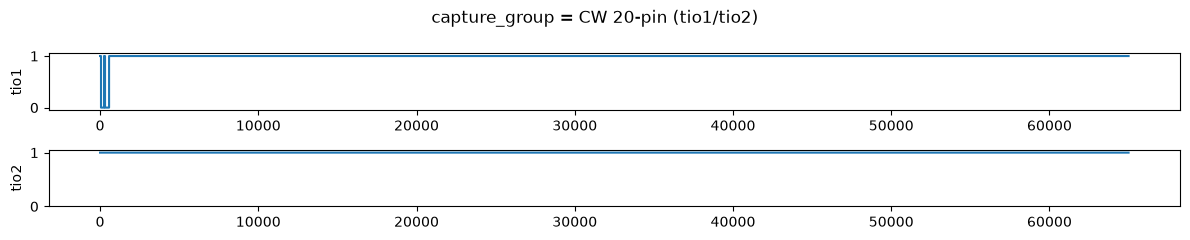

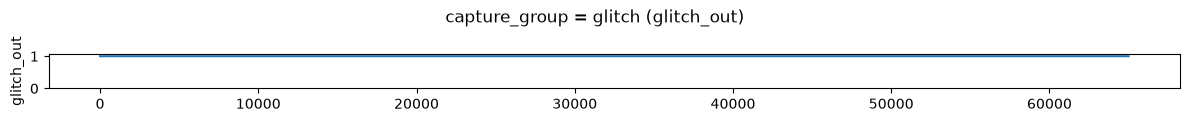

In [3]:
import sys
import time
import chipwhisperer as cw
import numpy as np
import matplotlib.pyplot as plt
import struct

def rx(n, timeout=300):
    """Read up to n bytes; returns fewer on timeout."""
    return ser.read(n, timeout=timeout).encode("latin-1")

def tx(data):
    for b in data:
        ser.write(bytes([b]))
        if BYTE_GAP:
            time.sleep(BYTE_GAP)

def enter_bootloader():
    """BOOT0 high, reset, then send 0x7F for auto-baud."""
    for _ in range(RETRIES):
        scope.io.pdic = "high"
        time.sleep(0.05)
        scope.io.nrst = "low"
        time.sleep(0.2)
        scope.io.nrst = "high_z"
        time.sleep(0.5)
        ser.flush()
        tx(b"\x7f")
        reply = rx(1)
        if reply == b"\x79":
            return
        print(f"  handshake reply: {reply.hex() or '(none)'}")
    raise RuntimeError("no ACK to 0x7F handshake")


def cmd(code):
    ser.flush()                       # resync: drop leftovers
    tx(bytes([code, code ^ 0xFF]))
    return rx(1)


def read_mem(addr, length):
    """Read Memory command (0x11), length 1..256."""
    if cmd(0x11) != b"\x79":
        raise RuntimeError("Read Memory NACK")
    a = addr.to_bytes(4, "big")
    tx(a + bytes([a[0] ^ a[1] ^ a[2] ^ a[3]]))
    if rx(1) != b"\x79":
        raise RuntimeError(f"address NACK at 0x{addr:08X}")
    tx(bytes([length - 1, (length - 1) ^ 0xFF]))
    if rx(1) != b"\x79":
        raise RuntimeError("length NACK")
    data = rx(length, timeout=1000)
    if len(data) != length:
        raise RuntimeError(f"short read at 0x{addr:08X}: {len(data)}/{length}")
    return data


def read_chunk_with_retry(addr, length):
    for attempt in range(RETRIES):
        try:
            return read_mem(addr, length)
        except RuntimeError as e:
            print(f"\n  retry {attempt + 1}/{RETRIES}: {e}")
            enter_bootloader()        # clean state, then try again
    raise RuntimeError(f"giving up at 0x{addr:08X}")

def init_logic_analyser(scope):
    scope.errors.clear()
    scope.adc.segments = 1
    scope.gain.db = 25
    
    scope.trigger.module = "basic"
    scope.trigger.triggers = "tio1"
    scope.glitch.trigger_src = "ext_single"   # glitch also fires on that trigger
    
    # --- Logic analyzer: record trigger + glitch signals ---
    scope.LA.enabled = True
    scope.LA.capture_group = 'CW 20-pin'      # glitch or CW 20-pin
    # other groups: 'CW 20-pin' (shows your trigger pin / IO), 'USB'
    scope.LA.capture_depth = 2000
    scope.LA.trigger_source = 'capture'     
    scope.LA.oversampling_factor = 1       # 1 = highest time resolution
    scope.LA.downsample = 1



FLASH_BASE = 0x08000000
FLASH_SIZE = 512 * 1024      # STM32L452RE: 512 KB
FLASH_SIZE = 256      # test
CHUNK = 64                   # SAM3U RX buffer holds only 128-200 bytes
BAUD = 115200
BYTE_GAP = 0.01              # back-to-back bytes get NACKed by the bootloader
RETRIES = 3

out_path = "flash_dump.bin"
size = FLASH_SIZE

try:
    scope.dis()
except:
    pass

scope = cw.scope()
scope.default_setup()
target = cw.target(scope, cw.targets.SimpleSerial)
scope.io.tio1 = "serial_tx"
scope.io.tio2 = "serial_rx"

ser = target.ser
ser.setBaud(BAUD)
ser.setParity("even")

init_logic_analyser(scope)


enter_bootloader()

# Get ID as a sanity check (expect 0462 for the L45x family)
if cmd(0x02) == b"\x79":
    n = rx(1)[0]
    pid = rx(n + 1)
    rx(1)
    print("product ID:", pid.hex())

t0 = time.time()
off = 0

import matplotlib.pyplot as plt

def capture_with_la(group, addr, length, glitch=false):
    """Arm LA + scope, trigger a flash read, and return the LA signals."""
    scope.errors.clear()
    scope.LA.enabled = True
    scope.LA.capture_group = group
    scope.LA.capture_depth = 65000
    scope.LA.trigger_source = 'capture'
    scope.LA.oversampling_factor = 1
    scope.LA.downsample = 1

    scope.LA.arm()
    scope.arm()

    data = read_chunk_with_retry(addr, length)

    timed_out = scope.capture()
    if timed_out:
        print(f"Timeout - no trigger ({group})")

    raw = scope.LA.read_capture_data()

    sigs = {}
    for i in range(9):  # each group has 9 signals
        try:
            sigs[i] = scope.LA.extract(raw, i)
        except Exception:
            break

    scope.LA.enabled = False
    return sigs, data


addr = FLASH_BASE + off
length = min(CHUNK, size - off)

# --- Pass 1: TIO1 / TIO2 on the 20-pin group ---
sigs1, data1 = capture_with_la('CW 20-pin', addr, length)
io_labels = {0: "tio1", 1: "tio2"}  # bits 0,1 of 'CW 20-pin'
io_sigs = {io_labels[i]: s for i, s in sigs1.items() if i in io_labels}

# --- Pass 2: glitch internals ---
sigs2, data2 = capture_with_la('glitch', addr, length)
glitch_sigs = {"glitch_out": sigs2[0]} if 0 in sigs2 else {}

if data1 != data2:
    print("Warning: the two passes read different data; timing may not line up.")

# --- Plot pass 1 ---
n1 = len(io_sigs)
fig1, axes1 = plt.subplots(n1, 1, figsize=(12, 1.2 * n1), sharex=False, squeeze=False)
fig1.suptitle("capture_group = CW 20-pin (tio1/tio2)")
for ax, (name, s) in zip(axes1[:, 0], io_sigs.items()):
    ax.step(range(len(s)), s, where='post')
    ax.set_ylabel(name)
    ax.set_yticks([0, 1])
plt.tight_layout()
plt.show()

# --- Plot pass 2 ---
n2 = len(glitch_sigs)
fig2, axes2 = plt.subplots(n2, 1, figsize=(12, 1.2 * n2), sharex=False, squeeze=False)
fig2.suptitle("capture_group = glitch (glitch_out)")
for ax, (name, s) in zip(axes2[:, 0], glitch_sigs.items()):
    ax.step(range(len(s)), s, where='post')
    ax.set_ylabel(name)
    ax.set_yticks([0, 1])
plt.tight_layout()
plt.show()

In [8]:
print(scope.errors)


sam_errors      = False
sam_led_setting = Default
XADC errors     = False
ADC errors      = segmenting error, trigger too soon error, 
extclk error    = False
trace errors    = False

